# Student Performance Analyzer

Predicting the final math grade (**G3**, scale 0-20) of Portuguese secondary-school students, and testing how much of that prediction comes from earlier grades (G1, G2) versus everything else.

**Dataset:** UCI *Student Performance* - math course (`student-mat.csv`, 395 students, 33 columns). Cortez & Silva (2008).

**Sections:** a) data check, b) EDA, c) preprocessing, d) models, e) G1/G2 check, f) pass/fail classifier, g) permutation importance, h) limitations.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, precision_score,
                             recall_score)
from sklearn.model_selection import KFold, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# WHY a fixed seed: every random choice (split, folds, forest) is repeatable,
# so anyone who re-runs this notebook gets the same numbers.
SEED = 42
np.random.seed(SEED)

# WHY find ROOT: the notebook lives in notebooks/, but figures and data live one level up.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(ROOT / "data"))
from download_data import load_student_mat  # downloads the CSV on first run

sns.set_theme(style="whitegrid")
print("Setup done. Figures will be saved to:", FIG_DIR)

Setup done. Figures will be saved to: /home/claude/student-performance-analyzer/reports/figures


## a) Data check

**What this does:** loads the data and checks size, missing values and column types before any analysis.

**Why:** if the data is broken (wrong file, missing values, numbers stored as text), every later result is wrong. This is the cheapest bug to catch.

**Be ready to explain:** why the file needs `sep=";"`, and why 0 missing values does *not* mean the data is clean (see the zero grades below).

In [2]:
df = load_student_mat()

print("Shape (rows, columns):", df.shape)
print("Total missing values :", int(df.isna().sum().sum()))
print()
print("Column types:")
numeric_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
text_cols = [c for c in df.columns if c not in numeric_cols]
print(f"  numeric ({len(numeric_cols)}):", numeric_cols)
print(f"  text/categorical ({len(text_cols)}):", text_cols)
print()
print("Students with a final grade of 0:", int((df['G3'] == 0).sum()),
      "-> kept in the data, see EDA and limitations")
df.head()

Shape (rows, columns): (395, 33)
Total missing values : 0

Column types:
  numeric (16): ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
  text/categorical (17): ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Students with a final grade of 0: 38 -> kept in the data, see EDA and limitations


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


**Reading:** 395 rows, 33 columns, 0 missing values. 16 columns are numeric and 17 are text, so 17 columns need encoding. "No missing values" is good, but 38 students (about 10%) have G3 = 0. That is a data-quality question, not a missing-value one, and it matters later.

## b) Exploratory data analysis

**What this does:** four plots that show what the target looks like and which simple relationships exist.

**Why:** you should look at the data before modelling. These plots also tell you what to expect: a weak relationship in EDA means a model should not do miracles.

**Be ready to explain:** each plot in one sentence, and why a correlation in a plot is not proof that one thing causes the other.

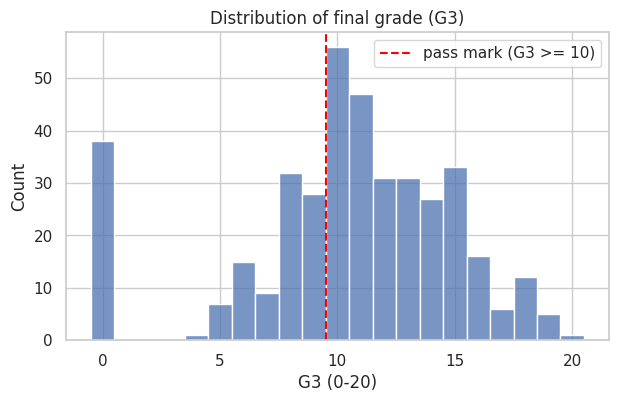

Mean G3 = 10.42, median = 11
Pass rate (G3 >= 10) = 67.1%
Zero grades: 38


In [3]:
# 1) Grade distribution (G3 is an integer from 0 to 20)
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df["G3"], bins=21, binrange=(-0.5, 20.5), ax=ax)
ax.axvline(9.5, color="red", linestyle="--", label="pass mark (G3 >= 10)")
ax.set_title("Distribution of final grade (G3)")
ax.set_xlabel("G3 (0-20)")
ax.legend()
plt.savefig(FIG_DIR / "01_g3_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Mean G3 = {df['G3'].mean():.2f}, median = {df['G3'].median():.0f}")
print(f"Pass rate (G3 >= 10) = {(df['G3'] >= 10).mean():.1%}")
print(f"Zero grades: {(df['G3'] == 0).sum()}")

**Reading:** grades centre around 10-11 (mean 10.42) and 67% of students pass. There is a separate spike at 0 that does not belong to the bell-shaped part of the distribution. The dataset does not say why, so treat any explanation (for example "did not sit the final assessment") as an assumption, not a fact.

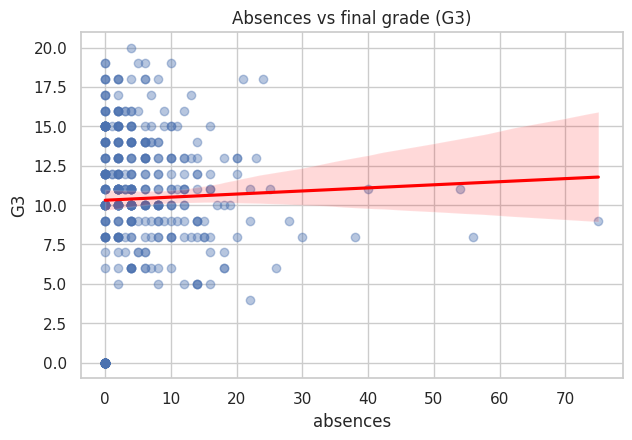

Pearson  correlation (absences, G3): 0.034
Spearman correlation (absences, G3): 0.018
Max absences: 75 | students with 0 absences: 115

Zero-grade students: 38; of them with absences == 0: 38
Share with G3 == 0 among students with absences == 0: 33% | among students with absences > 0: 0%
Pearson correlation (absences, G3) excluding zero-grade students: -0.213


In [4]:
# 2) Absences vs final grade
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.regplot(data=df, x="absences", y="G3", scatter_kws={"alpha": 0.4},
            line_kws={"color": "red"}, ax=ax)
ax.set_title("Absences vs final grade (G3)")
plt.savefig(FIG_DIR / "02_absences_vs_g3.png", dpi=150, bbox_inches="tight")
plt.show()

# WHY Spearman as well: absences has a few extreme values, and Spearman (rank-based)
# is less affected by outliers than Pearson.
print("Pearson  correlation (absences, G3):", round(df["absences"].corr(df["G3"]), 3))
print("Spearman correlation (absences, G3):", round(df["absences"].corr(df["G3"], method="spearman"), 3))
print("Max absences:", df["absences"].max(), "| students with 0 absences:", int((df['absences'] == 0).sum()))

# WHY this check: the plot shows a cluster of G3 = 0 sitting at absences = 0. Let us measure it.
zero = df[df["G3"] == 0]
print(f"\nZero-grade students: {len(zero)}; of them with absences == 0: {int((zero['absences'] == 0).sum())}")
print(f"Share with G3 == 0 among students with absences == 0: {(df[df['absences'] == 0]['G3'] == 0).mean():.0%}"
      f" | among students with absences > 0: {(df[df['absences'] > 0]['G3'] == 0).mean():.0%}")
nonzero = df[df["G3"] > 0]
print("Pearson correlation (absences, G3) excluding zero-grade students:",
      round(nonzero["absences"].corr(nonzero["G3"]), 3))

**Reading:** across all students, absences and G3 look unrelated (Pearson 0.03). That is misleading. All 38 zero-grade students have absences = 0, so the group with no recorded absences contains many zero grades. Remove those 38 and the correlation turns negative (-0.21), as you would expect. Two opposite effects cancel in the simple correlation. **Lesson: a correlation near zero does not mean "no relationship".**

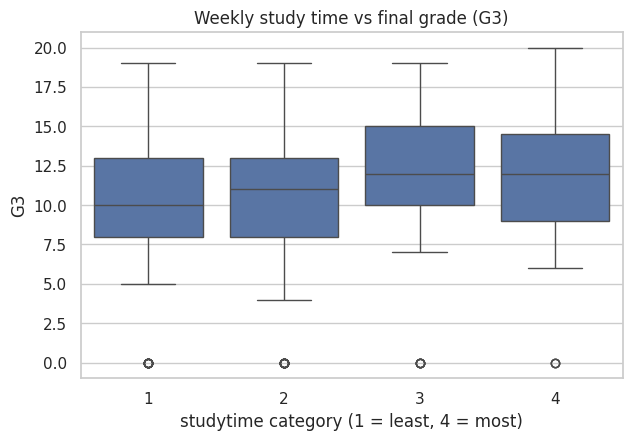

           count   mean
studytime              
1            105  10.05
2            198  10.17
3             65  11.40
4             27  11.26


In [5]:
# 3) Study time vs final grade (studytime: 1 = <2h, 2 = 2-5h, 3 = 5-10h, 4 = >10h per week)
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=df, x="studytime", y="G3", ax=ax)
ax.set_title("Weekly study time vs final grade (G3)")
ax.set_xlabel("studytime category (1 = least, 4 = most)")
plt.savefig(FIG_DIR / "03_studytime_vs_g3.png", dpi=150, bbox_inches="tight")
plt.show()

print(df.groupby("studytime")["G3"].agg(["count", "mean"]).round(2))

**Reading:** students in the two higher study-time groups (3-4, i.e. more than 5 hours a week) average about 1.2 grade points more than those in groups 1-2 (about 11.3 vs 10.1). The boxes overlap heavily, so study time alone predicts little. Group 4 has only 27 students, so its average is shaky.

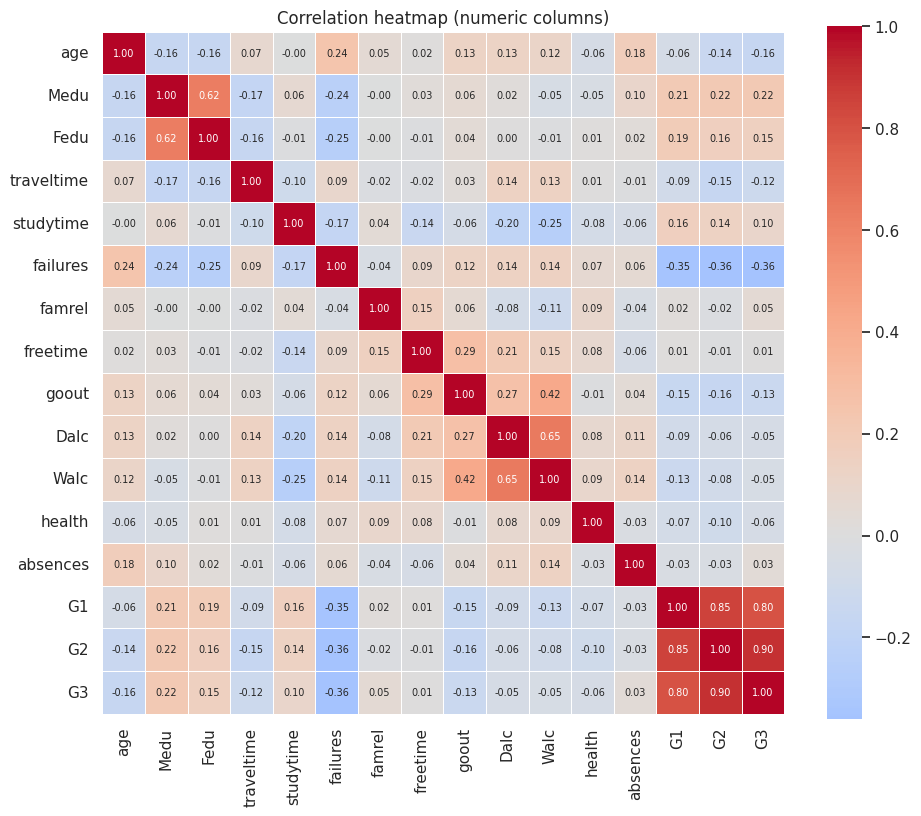

Correlation with G3, strongest first:
G2            0.90
G1            0.80
failures     -0.36
Medu          0.22
age          -0.16
Fedu          0.15
goout        -0.13
traveltime   -0.12
Name: G3, dtype: float64


In [6]:
# 4) Correlation heatmap of all numeric columns (including G1, G2, G3)
corr = df.select_dtypes(include="number").corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True,
            linewidths=0.5, annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlation heatmap (numeric columns)")
plt.savefig(FIG_DIR / "04_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

print("Correlation with G3, strongest first:")
print(corr["G3"].drop("G3").sort_values(key=abs, ascending=False).round(2).head(8))

**Reading:** G2 (0.90) and G1 (0.80) correlate with G3 far more strongly than anything else. After them the strongest is `failures` (-0.36), then `Medu`, mother's education (0.22). Most other columns are below 0.2 in absolute value. This previews section e: with G1/G2 the task is easy, without them it is hard.

## c) Preprocessing

**What this does:** (1) splits students into train (80%) and test (20%); (2) defines a one-hot encoder that turns text columns such as `school = GP/MS` into 0/1 columns, because scikit-learn models need numbers.

**Why:**
- *Split first, then keep the test set untouched.* The test set stands in for "new students the model has never seen".
- *`stratify`* keeps the pass/fail ratio the same in train and test (important with only 395 rows).
- *The encoder sits inside a Pipeline.* During cross-validation it is re-fitted on each training fold, so nothing from a validation fold leaks into preprocessing. For one-hot encoding the effect is tiny, but the habit matters for scaling and imputing.
- *`drop="first"`* removes one redundant column per category (avoids the "dummy variable trap" that confuses Linear Regression).

**Be ready to explain:** why the split happens before everything else, and what a Pipeline protects you from.

In [7]:
TARGET = "G3"
X_all = df.drop(columns=[TARGET])
y = df[TARGET]
y_pass = (y >= 10).astype(int)          # 1 = pass, 0 = fail (used in section f)

# Two feature sets, used in sections d, e, f, g
FEATURES_WITH = list(X_all.columns)                                   # everything incl. G1, G2
FEATURES_WITHOUT = [c for c in X_all.columns if c not in ("G1", "G2")]  # no earlier grades

# One split for the whole project. stratify=y_pass keeps the pass rate equal in both parts.
X_train_all, X_test_all, y_train, y_test = train_test_split(
    X_all, y, test_size=0.2, random_state=SEED, stratify=y_pass)
ytr_pass, yte_pass = y_pass.loc[y_train.index], y_pass.loc[y_test.index]

def make_preprocessor(X):
    # WHY not hard-code column names: detect text columns from the data itself.
    cat_cols = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
    onehot = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
    # remainder="passthrough": numeric columns go through unchanged
    return ColumnTransformer([("onehot", onehot, cat_cols)], remainder="passthrough")

print(f"Train: {len(X_train_all)} students | Test: {len(X_test_all)} students")
print(f"Pass rate  train: {ytr_pass.mean():.1%} | test: {yte_pass.mean():.1%}")

for name, cols in [("with G1+G2", FEATURES_WITH), ("without G1+G2", FEATURES_WITHOUT)]:
    prep = make_preprocessor(X_train_all[cols])
    encoded = prep.fit_transform(X_train_all[cols])
    print(f"Features {name}: {len(cols)} original columns -> {encoded.shape[1]} columns after one-hot encoding")

print("\nExample encoded column names:", list(prep.get_feature_names_out()[:6]))

Train: 316 students | Test: 79 students
Pass rate  train: 67.1% | test: 67.1%
Features with G1+G2: 32 original columns -> 41 columns after one-hot encoding
Features without G1+G2: 30 original columns -> 39 columns after one-hot encoding

Example encoded column names: ['onehot__school_MS', 'onehot__sex_M', 'onehot__address_U', 'onehot__famsize_LE3', 'onehot__Pstatus_T', 'onehot__Mjob_health']


## d) Models: baseline, Linear Regression, Random Forest

**What this does:** predicts G3 with three models and scores each with **5-fold cross-validation** on the training set (the test set is used only once at the end, as a final check).

**Why these three:**
- *Mean baseline* always predicts the average grade. Any real model must beat it, otherwise it has learned nothing.
- *Linear Regression* is simple and interpretable.
- *Random Forest* can capture non-linear effects and interactions, with little tuning.

**Metrics:** MAE = average error in grade points; RMSE = like MAE but punishes big mistakes more; R2 = share of grade variation explained (0 = no better than the mean, 1 = perfect, negative = worse than the mean).

**Be ready to explain:** why cross-validation gives a more trustworthy number than one split (especially with ~316 training rows), and what R2 = 0 means.

In [8]:
MODELS = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
}
# WHY shuffle=True: rows may be ordered (e.g. by school); shuffling makes the folds comparable.
CV = KFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"mae": "neg_mean_absolute_error",
           "rmse": "neg_root_mean_squared_error",
           "r2": "r2"}

def run_regressors(feature_cols, label):
    """5-fold CV on the training set, plus one final score on the held-out test set."""
    rows = []
    Xtr, Xte = X_train_all[feature_cols], X_test_all[feature_cols]
    for name, model in MODELS.items():
        pipe = Pipeline([("prep", make_preprocessor(Xtr)), ("model", clone(model))])
        cv_res = cross_validate(pipe, Xtr, y_train, cv=CV, scoring=SCORING)
        pipe.fit(Xtr, y_train)
        rows.append({
            "Features": label, "Model": name,
            "MAE": -cv_res["test_mae"].mean(), "MAE_sd": cv_res["test_mae"].std(),
            "RMSE": -cv_res["test_rmse"].mean(), "RMSE_sd": cv_res["test_rmse"].std(),
            "R2": cv_res["test_r2"].mean(), "R2_sd": cv_res["test_r2"].std(),
            "Test_R2": pipe.score(Xte, y_test),
        })
    return pd.DataFrame(rows)

def pretty(res):
    """Format as 'mean +/- sd' for reading; the numeric table is what we save."""
    out = res[["Features", "Model"]].copy()
    for m in ["MAE", "RMSE", "R2"]:
        out[f"CV {m}"] = [f"{a:.2f} +/- {b:.2f}" for a, b in zip(res[m], res[f"{m}_sd"])]
    out["Test R2"] = res["Test_R2"].round(2)
    return out.to_string(index=False)

results_with = run_regressors(FEATURES_WITH, "With G1+G2")
print("5-fold CV on the training set (mean +/- std across folds):\n")
print(pretty(results_with))

5-fold CV on the training set (mean +/- std across folds):

  Features             Model        CV MAE       CV RMSE          CV R2  Test R2
With G1+G2     Mean baseline 3.45 +/- 0.42 4.58 +/- 0.45 -0.00 +/- 0.00    -0.00
With G1+G2 Linear Regression 1.40 +/- 0.11 2.05 +/- 0.19  0.79 +/- 0.08     0.77
With G1+G2     Random Forest 1.01 +/- 0.14 1.58 +/- 0.30  0.87 +/- 0.06     0.88


**Reading (all features, including G1 and G2):** both models beat the mean baseline by a wide margin. Random Forest is best: cross-validated MAE 1.01 grade points and R2 0.87 (test R2 0.88), against MAE 3.45 and R2 0.00 for the baseline. Linear Regression reaches R2 0.79. CV and test scores are close, so the CV estimate looks fair. Do not be impressed yet: these models were handed G1 and G2, which is most of the answer (see e).

## e) The G1/G2 check ("leakage" check)

**What this does:** repeats section d with G1 and G2 removed, then puts both versions in one table.

**Why:** G1 and G2 are the grades of the 1st and 2nd period; G3 is the final grade of the same year. A model that sees them is mostly extrapolating a trend it was handed. The dataset authors warn that predicting G3 without G1/G2 is harder but much more useful, because it works *early*, when a teacher can still act.

**A precise word choice:** G1/G2 are not leakage in the strict sense (they are real information, not a copy of the answer). They become a problem only if you want to predict *before* those grades exist. So the real question is: *at what moment will the prediction be used?*

**Be ready to explain:** the difference between strict leakage and a feature that is unavailable at prediction time.

In [9]:
results_without = run_regressors(FEATURES_WITHOUT, "Without G1+G2")
comparison = pd.concat([results_with, results_without], ignore_index=True)

print(pretty(comparison))

# Save the numeric table for the README
comparison.round(4).to_csv(ROOT / "reports" / "results_table.csv", index=False)

# Gap in R2 per model
gap = (results_with.set_index("Model")["R2"] - results_without.set_index("Model")["R2"]).round(2)
print("\nDrop in CV R2 when G1+G2 are removed:\n", gap.to_string())

     Features             Model        CV MAE       CV RMSE          CV R2  Test R2
   With G1+G2     Mean baseline 3.45 +/- 0.42 4.58 +/- 0.45 -0.00 +/- 0.00    -0.00
   With G1+G2 Linear Regression 1.40 +/- 0.11 2.05 +/- 0.19  0.79 +/- 0.08     0.77
   With G1+G2     Random Forest 1.01 +/- 0.14 1.58 +/- 0.30  0.87 +/- 0.06     0.88
Without G1+G2     Mean baseline 3.45 +/- 0.42 4.58 +/- 0.45 -0.00 +/- 0.00    -0.00
Without G1+G2 Linear Regression 3.28 +/- 0.20 4.32 +/- 0.32  0.07 +/- 0.25    -0.09
Without G1+G2     Random Forest 2.96 +/- 0.38 3.86 +/- 0.41  0.29 +/- 0.06     0.27

Drop in CV R2 when G1+G2 are removed:
 Model
Mean baseline        0.00
Linear Regression    0.72
Random Forest        0.58


**What the gap means (3 sentences):**

Removing G1 and G2 drops Random Forest from R2 0.87 to 0.29 (MAE 1.01 to 2.96) and Linear Regression from 0.79 to 0.07, so nearly all of the strong performance in section d came from the earlier grades and not from the background and behaviour columns. Without them the models are only modestly better than guessing the class average (MAE 2.96 vs 3.45), and Linear Regression is barely above the baseline in cross-validation and below it on the test set (R2 -0.09), so predicting final grades from background features alone is hard with this data. G1 and G2 are not leakage in the strict sense, but they only exist once the school year is well under way, which makes the "with" rows useless for early warning; the honest early-warning numbers are the "Without G1+G2" rows.

## f) Pass/fail classifier (G3 >= 10)

**What this does:** a Random Forest classifier that predicts pass (1) or fail (0), trained on the training set and scored once on the test set (79 students). Pass is the "positive" class.

**Why compare with a majority-class baseline:** 67% of students pass, so a model that says "pass" for everyone already gets ~67% accuracy. Accuracy alone is misleading here.

**How to read the metrics:**
- *Precision* = of the students predicted to pass, how many really passed.
- *Recall* = of the students who really passed, how many did we catch.
- *F1* = a balance of the two.
- For an early-warning use, what matters most is catching students who will **fail**, so the report below also shows recall for the fail class.

**Be ready to explain:** why accuracy can look fine while the model is useless, and what each cell of the confusion matrix means.

In [10]:
def run_classifier(feature_cols, label, model):
    Xtr, Xte = X_train_all[feature_cols], X_test_all[feature_cols]
    pipe = Pipeline([("prep", make_preprocessor(Xtr)), ("model", clone(model))])
    pipe.fit(Xtr, ytr_pass)
    pred = pipe.predict(Xte)
    metrics = {
        "Model": label,
        "Accuracy": accuracy_score(yte_pass, pred),
        "Precision": precision_score(yte_pass, pred, zero_division=0),
        "Recall": recall_score(yte_pass, pred, zero_division=0),
        "F1": f1_score(yte_pass, pred, zero_division=0),
    }
    return metrics, pred

rf_clf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
base_clf = DummyClassifier(strategy="most_frequent")

m_base, _ = run_classifier(FEATURES_WITHOUT, "Majority-class baseline", base_clf)
m_without, pred_without = run_classifier(FEATURES_WITHOUT, "Random Forest, without G1+G2", rf_clf)
m_with, pred_with = run_classifier(FEATURES_WITH, "Random Forest, with G1+G2", rf_clf)

clf_table = pd.DataFrame([m_base, m_without, m_with]).set_index("Model").round(3)
print(f"Test set ({len(yte_pass)} students). Positive class = pass.\n")
print(clf_table)

print("\nFull report, Random Forest WITHOUT G1+G2 (0 = fail, 1 = pass):")
print(classification_report(yte_pass, pred_without, target_names=["fail", "pass"], zero_division=0))

# WHY also cross-validate: 79 test students is small, so one test score is noisy.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
pipe_cv = Pipeline([("prep", make_preprocessor(X_train_all[FEATURES_WITHOUT])),
                    ("model", clone(rf_clf))])
cv_clf = cross_validate(pipe_cv, X_train_all[FEATURES_WITHOUT], ytr_pass, cv=skf,
                        scoring=["accuracy", "f1"])
print(f"5-fold CV on the training set (no G1/G2): accuracy {cv_clf['test_accuracy'].mean():.2f} "
      f"+/- {cv_clf['test_accuracy'].std():.2f}, F1 {cv_clf['test_f1'].mean():.2f} +/- {cv_clf['test_f1'].std():.2f}")

Test set (79 students). Positive class = pass.

                              Accuracy  Precision  Recall     F1
Model                                                           
Majority-class baseline          0.671      0.671   1.000  0.803
Random Forest, without G1+G2     0.646      0.687   0.868  0.767
Random Forest, with G1+G2        0.886      0.958   0.868  0.911

Full report, Random Forest WITHOUT G1+G2 (0 = fail, 1 = pass):
              precision    recall  f1-score   support

        fail       0.42      0.19      0.26        26
        pass       0.69      0.87      0.77        53

    accuracy                           0.65        79
   macro avg       0.55      0.53      0.51        79
weighted avg       0.60      0.65      0.60        79



5-fold CV on the training set (no G1/G2): accuracy 0.72 +/- 0.05, F1 0.81 +/- 0.03


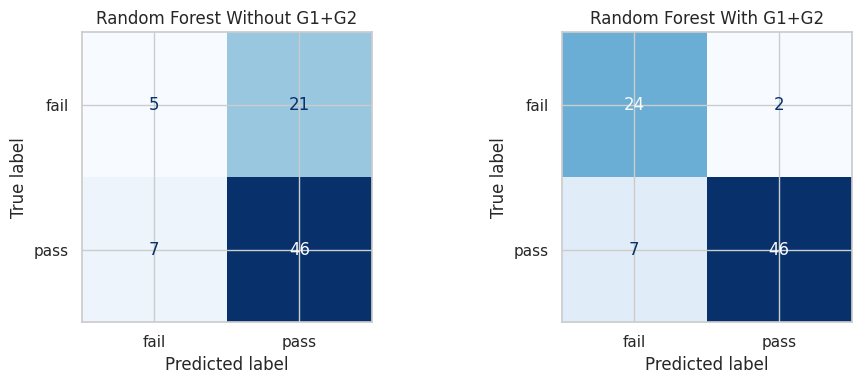

Without G1+G2: 5 fails caught, 21 fails missed (predicted pass), 7 passes wrongly flagged as fail, 46 passes correct.
With G1+G2   : 24 fails caught, 2 fails missed (predicted pass), 7 passes wrongly flagged as fail, 46 passes correct.


In [11]:
# Confusion matrices: rows = true label, columns = predicted label
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, title in [(axes[0], pred_without, "Without G1+G2"), (axes[1], pred_with, "With G1+G2")]:
    cm = confusion_matrix(yte_pass, pred)
    ConfusionMatrixDisplay(cm, display_labels=["fail", "pass"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"Random Forest {title}")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

for label, pred in [("Without G1+G2", pred_without), ("With G1+G2   ", pred_with)]:
    tn, fp, fn, tp = confusion_matrix(yte_pass, pred).ravel()
    print(f"{label}: {tn} fails caught, {fp} fails missed (predicted pass), "
          f"{fn} passes wrongly flagged as fail, {tp} passes correct.")

**Reading:**
- **With G1+G2** the classifier is strong: accuracy 0.89, precision 0.96, recall 0.87, F1 0.91, and it catches 24 of the 26 failing students.
- **Without G1+G2** test accuracy is 0.65, which is *below* the 0.67 you get by predicting "pass" for everyone. It catches only 5 of 26 failing students (fail recall 0.19). Its high pass-recall (0.87) comes from leaning towards "pass", not from skill.
- Cross-validated accuracy on the training set (0.72 +/- 0.05) is a bit higher than test accuracy (0.65). With 79 test students, each student is worth about 1.3 points of accuracy, so one split is noisy. A fair summary: **without earlier grades the classifier is roughly at baseline level, with no reliable ability to flag at-risk students.**

## g) Permutation importance (model without G1/G2)

**What this does:** takes the Random Forest regressor trained *without* G1/G2, then shuffles one original column at a time in the **test set** and measures how much R2 drops. A big drop = the model relied on that column.

**Why this method:** it works for any model and is measured on unseen data. It is done on the original columns (before one-hot encoding), so `Mjob` is one bar, not five.

**Be ready to explain:** why permutation importance is more trustworthy than the forest's built-in importance (which is computed on training data and favours columns with many distinct values), and why "important to the model" does not mean "causes the grade".

Test R2 of this model: 0.27


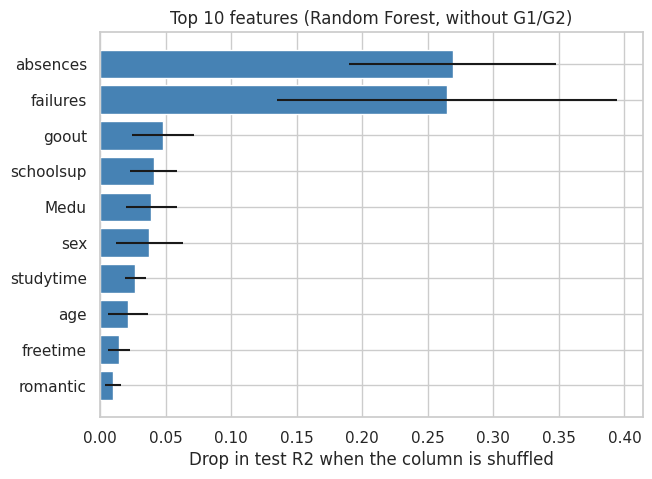

  feature  importance    sd
 absences       0.269 0.079
 failures       0.265 0.130
    goout       0.048 0.024
schoolsup       0.041 0.018
     Medu       0.039 0.019
      sex       0.038 0.026
studytime       0.027 0.008
      age       0.021 0.015
 freetime       0.014 0.009
 romantic       0.010 0.006

Columns with importance <= 0 (shuffling did not hurt): 11 of 30


In [12]:
Xtr, Xte = X_train_all[FEATURES_WITHOUT], X_test_all[FEATURES_WITHOUT]
rf_pipe = Pipeline([("prep", make_preprocessor(Xtr)),
                    ("model", RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1))])
rf_pipe.fit(Xtr, y_train)
print(f"Test R2 of this model: {rf_pipe.score(Xte, y_test):.2f}")

perm = permutation_importance(rf_pipe, Xte, y_test, n_repeats=30, random_state=SEED, scoring="r2")
importance = (pd.DataFrame({"feature": FEATURES_WITHOUT,
                            "importance": perm.importances_mean,
                            "sd": perm.importances_std})
              .sort_values("importance", ascending=False))
top10 = importance.head(10)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top10["feature"][::-1], top10["importance"][::-1], xerr=top10["sd"][::-1], color="steelblue")
ax.set_xlabel("Drop in test R2 when the column is shuffled")
ax.set_title("Top 10 features (Random Forest, without G1/G2)")
plt.savefig(FIG_DIR / "06_permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()

print(top10.round(3).to_string(index=False))
print("\nColumns with importance <= 0 (shuffling did not hurt):", int((importance['importance'] <= 0).sum()), "of", len(importance))

In [13]:
# Sanity check: does 'absences' stay important if the 38 zero-grade students are removed?
keep = y > 0
Xk_tr, Xk_te, yk_tr, yk_te = train_test_split(
    X_all.loc[keep, FEATURES_WITHOUT], y[keep], test_size=0.2, random_state=SEED)
pipe_k = Pipeline([("prep", make_preprocessor(Xk_tr)),
                   ("model", RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1))])
pipe_k.fit(Xk_tr, yk_tr)
perm_k = permutation_importance(pipe_k, Xk_te, yk_te, n_repeats=30, random_state=SEED, scoring="r2")
imp_k = (pd.DataFrame({"feature": FEATURES_WITHOUT, "importance": perm_k.importances_mean})
         .sort_values("importance", ascending=False).head(5))
print(f"Without zero-grade students ({keep.sum()} rows): test R2 = {pipe_k.score(Xk_te, yk_te):.2f}")
print(imp_k.round(3).to_string(index=False))

Without zero-grade students (357 rows): test R2 = 0.25
  feature  importance
 failures       0.070
schoolsup       0.065
studytime       0.039
     Mjob       0.038
      age       0.021


**Reading in plain English:**
- `failures` (number of past class failures) is the clearest real signal: average G3 is 11.3 for students with no past failures, 8.1 with one, 6.2 with two and 5.7 with three.
- `absences` ranks first, but do not read this as "skipping school lowers grades". As section b showed, all zero-grade students have absences = 0, and the forest uses that pattern to spot them. The check above confirms it: without the 38 zero-grade students, `absences` drops out of the top 5 and the remaining importances are much smaller.
- After that the effects are small (about 0.05 or less): going out with friends, school support, mother's education, `sex`, study time. `sex` and `Medu` describe background, not effort; seeing them here is a pattern in this dataset, not a reason to use them in decisions (see h).
- Caution: this is measured on only 79 test students. For several features the spread (sd) is about as large as the value, so only the top few positions are trustworthy. "Important to the model" does not mean "causes the grade".

## h) Limitations

- **Small data.** 395 students (316 train, 79 test). Scores move noticeably with a different split, so differences of a few hundredths in R2 or accuracy should not be over-read. No hyperparameter tuning was done on purpose: with this little data, tuning mostly fits noise.
- **One school system, one subject, one period.** Two Portuguese schools, math only, data from about 2005-2006. Results do not transfer automatically to other countries, subjects or years (including Indian colleges).
- **Correlation is not causation.** A column that predicts grades (e.g. past failures, absences) is a *signal*, not necessarily a *cause*. Telling a student to "study more" because the model flagged study time would be an unsupported claim.
- **Zero grades.** 38 students have G3 = 0, which usually means the student did not take or complete the final assessment, not that they scored zero on ability. They are kept, but they are hard to predict and they pull the error up.
- **Sensitive attributes.** The data contains `sex`, `age`, parents' education and jobs, `address`, `famsize`, `Pstatus` and `romantic`. These describe a student's background, not their effort. Using them to decide who gets support, attention or opportunities would risk discriminating against students for things they cannot change, and a model can encode unfair patterns from the past. This project uses them only to study the data; any real system should drop them or audit them for bias first, and keep a human in the loop.
- **Not a deployable tool.** This is a learning project. No fairness audit, no calibration, no monitoring.